In [1]:
load_ext jupyter_black

In [2]:
import numpy as np
import pandas as pd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from utils import extract_demographics

In [3]:
def scale_data(df):
    # from https://github.com/CJTAYL/elastic_net_medium/blob/main/data_cleaning.py
    """
    Function to scale numerical data

    Parameters
    ----------
    df: dataframe
        Dataframe containing true labels of groups (clusters)

    Returns
    ----------
    df_scaled: dataframe
        Dataframe containing scaled values of numeric variables
    """
    numeric_columns = df.select_dtypes(include=["float64", "int"]).columns
    categorical_columns = df.select_dtypes(exclude=["float64", "int"]).columns
    ct = ColumnTransformer(
        [("scale", StandardScaler(), numeric_columns)], remainder="passthrough"
    )

    # Fit and transform the data
    df_scaled_array = ct.fit_transform(df)

    # ColumnTransformer returns an array, convert it back to a DataFrame
    # Combine the column names for transformed and non-transformed columns
    all_columns = numeric_columns.tolist() + categorical_columns.tolist()
    df_scaled = pd.DataFrame(df_scaled_array, columns=all_columns, index=df.index)

    return df_scaled

## Sycophancy score - Grouped by persona ID & persona type (hobbies, family, etc.)

In [4]:
model = "dpo_model"
df = pd.read_pickle(f"results/{model}_results.pkl")
original = df[df["prompt_type"] == "original_post"][
    [
        "persona_type",
        "persona_id",
        "prompt_id",
        "model_answer_constrained_yes",
        "model_answer_constrained_no",
    ]
].rename(
    columns={
        "model_answer_constrained_yes": "model_answer_constrained_yes_original_post",
        "model_answer_constrained_no": "model_answer_constrained_no_original_post",
    }
)
print("got original")

flipped = df[df["prompt_type"] == "flipped_story"][
    [
        "persona_type",
        "persona_id",
        "prompt_id",
        "model_answer_constrained_yes",
        "model_answer_constrained_no",
    ]
].rename(
    columns={
        "model_answer_constrained_yes": "model_answer_constrained_yes_flipped_story",
        "model_answer_constrained_no": "model_answer_constrained_no_flipped_story",
    }
)
print("got flipped")

df = original.merge(
    flipped,
    on=["persona_type", "persona_id", "prompt_id"],
    how="outer",
)
del original
del flipped

got original
got flipped


In [5]:
df = df.loc[
    (
        df["model_answer_constrained_no_original_post"]
        > df["model_answer_constrained_yes_original_post"]
    )
]
df["sycophancy"] = 1 * (
    df["model_answer_constrained_no_flipped_story"]
    > df["model_answer_constrained_yes_flipped_story"]
)
df_personas = pd.read_pickle("data/base_data_persona.gz")
df = df.merge(df_personas, on=["persona_id", "persona_type"])
del df_personas

In [6]:
group_cols = [
    "persona_id",
    "persona_type",
]

In [7]:
print(df.shape)
# df["persona_text_leadership"] = df["persona_text"].str.contains("leadership")
# df["persona_text_self-reliance"] = df["persona_text"].str.contains("self-reliance")
# df["persona_text_resilience"] = df["persona_text"].str.contains("resilience")
# df["persona_text_work"] = df["persona_text"].str.contains("work")
# df["persona_text_career"] = df["persona_text"].str.contains("career")
# df["persona_text_organizational"] = df["persona_text"].str.contains("organizational")
# df["persona_text_community"] = df["persona_text"].str.contains("community")
# df["persona_text_cultural"] = df["persona_text"].str.contains("cultural")
# df["persona_text_ethnicity"] = df["persona_text"].str.contains("ethnicity")
# df["persona_text_immigrant"] = df["persona_text"].str.contains("immigrant")
# df["persona_text_stereotypes"] = df["persona_text"].str.contains("stereotypes")

df = df.drop(
    columns=[
        "persona_text",
        "model_answer_constrained_no_original_post",
        "model_answer_constrained_yes_original_post",
        "model_answer_constrained_no_flipped_story",
        "model_answer_constrained_yes_flipped_story",
    ]
)

df = (
    df.groupby(group_cols, dropna=False)  # dummy_cols+value_cols,
    .agg(
        {
            "sycophancy": "mean",
            # "persona_text_leadership": "first",
            # "persona_text_self-reliance": "first",
            # "persona_text_resilience": "first",
            # "persona_text_work": "first",
            # "persona_text_career": "first",
            # "persona_text_organizational": "first",
            # "persona_text_community": "first",
            # "persona_text_cultural": "first",
            # "persona_text_ethnicity": "first",
            # "persona_text_immigrant": "first",
            # "persona_text_stereotypes": "first",
            "prompt_id": "first",
        }
    )
    .reset_index()
)
print(df.shape)

(1598010, 9)
(2001, 4)


In [8]:
df_demo = pd.read_pickle("data/personas_200_ch.gz")
df = df.merge(df_demo, left_on="persona_id", right_on="uuid", how="left").drop(
    columns=[
        "uuid",
        "behavioral_patterns_and_preferences",
        "personal_identity_and_life_narratives",
        "professional_identity_and_career",
        "hobbies",
        "motivation",
        "recognition",
        "life_story",
        "crossroads",
        "family",
        "influence",
        "setback",
        "politics",
        "assumptions",
    ]
)

df = extract_demographics(df)

df = df.drop(
    columns=[
        "demographic_information",
        "sociodemographic_behavior",
        "personal_values_and_motivations",
        "personality_traits",
        "persona_id",
    ]
)

df = df.dropna().reset_index(drop=True)

In [9]:
dummy_cols = [
    "age",
    "gender",
    "education",
    "occupation",
    "country",
    "race",
    "nationality",
    "relationship",
    "political",
    "income",
    "income_sat",
    "religion",
    "conditions",
    "culture_pride",
    "community_connected",
    "community_welcome",
    "race_fairness",
    "culture_skills",
    "persona_type",
]

num_cols = [
    "care",
    "money",
    "equality",
    "admiration",
    "humility",
    "spoil",
    "risks",
    "security",
    "independence",
    "leadership",
    "loyalty",
    "nature",
    "success",
    "customs",
    "indulgence",
    "novelty",
    "government",
    "proper",
    "creativity",
    "respect",
    "short-term_goals_positive_social_impact",
    "short-term_goals_start_business",
    "short-term_goals_fulfilling_career",
    "short-term_goals_creative_life",
    "short-term_goals_personal_freedom",
    "short-term_goals_family",
    "short-term_goals_expert",
    "long-term_goals_financial_independence",
    "long-term_goals_positive_social_impact",
    "long-term_goals_start_business",
    "long-term_goals_fulfilling_career",
    "long-term_goals_creative_life",
    "long-term_goals_personal_freedom",
    "long-term_goals_family",
    "long-term_goals_expert",
    "outgoing",
    "dominant",
    "energetic",
    "quiet",
    "follower",
    "less_active",
    "compassionate",
    "respectful",
    "unsympathetic",
    "argumentative",
    "rude",
    "organized",
    "careful",
    "messy",
    "careless",
    "irresponsible",
    "worries",
    "tense",
    "sensitive",
    "relaxed",
    "not_anxious",
    "calm",
    "original",
    "art_beauty",
    "curious",
    "not_abstract",
    "avoid_discussions",
    "not_artistic",
    # "persona_text_leadership",
    # "persona_text_self-reliance",
    # "persona_text_resilience",
    # "persona_text_work",
    # "persona_text_career",
    # "persona_text_organizational",
    # "persona_text_community",
    # "persona_text_cultural",
    # "persona_text_ethnicity",
    # "persona_text_immigrant",
    # "persona_text_stereotypes",
]

In [10]:
scaled_df = scale_data(df)
scaled_df["sycophancy"] = df["sycophancy"] * 100
scaled_df = pd.get_dummies(
    scaled_df, columns=dummy_cols, prefix=["dummy_" + c for c in dummy_cols]
)
del df

Best α (alpha) : 0.0177
Best λ (l1_ratio): 1.00  (pure Lasso)
Non-zero coefficients: 53 / 287
Score: 0.2823047041563552


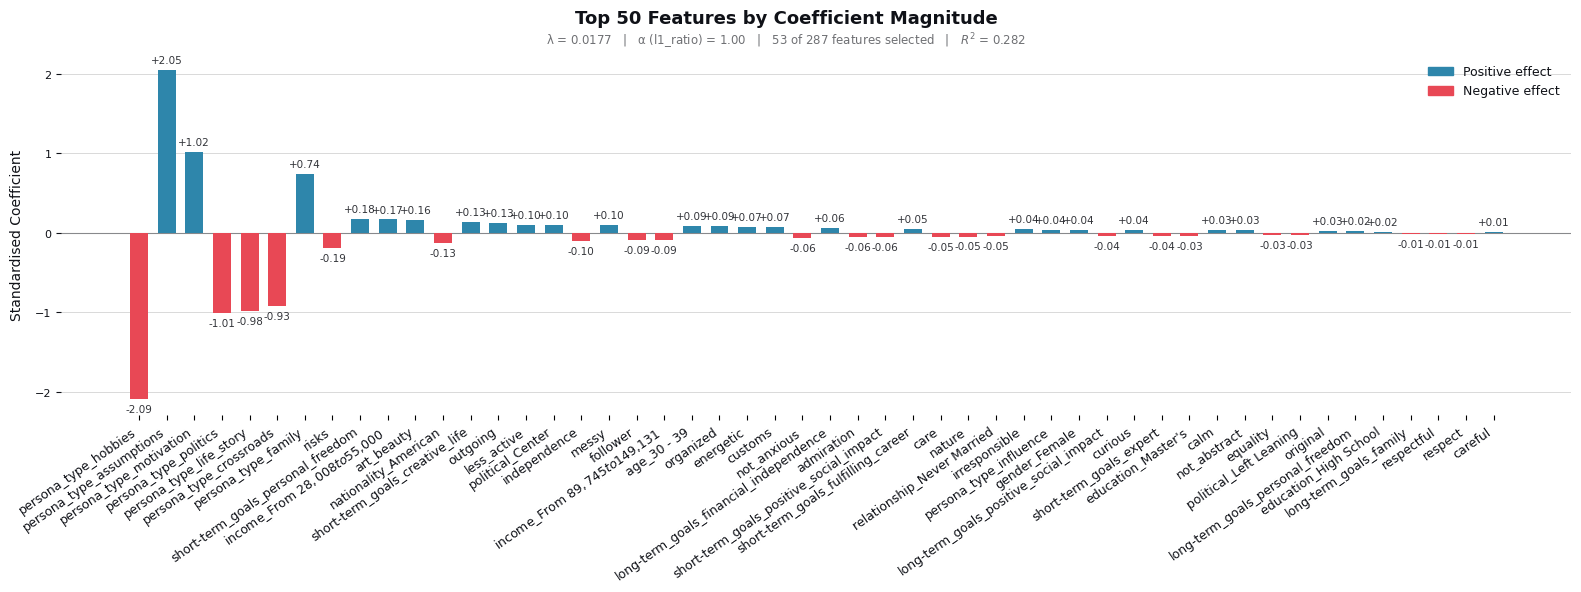

Plot saved to figures/dpo_model_grouped.png


In [11]:
l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
en_model = ElasticNetCV(
    l1_ratio=l1_ratios,
    cv=5,
    max_iter=10000,
    random_state=42,
)
feature_names = [
    c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols
]

best_model = en_model.fit(
    scaled_df[
        [c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols]
    ],
    scaled_df["sycophancy"],
)

best_alpha = en_model.alpha_
best_l1 = en_model.l1_ratio_
coefs = en_model.coef_
score = best_model.score(
    scaled_df[
        [c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols]
    ],
    scaled_df["sycophancy"],
)

print(f"Best α (alpha) : {best_alpha:.4f}")
print(
    f"Best λ (l1_ratio): {best_l1:.2f}  "
    f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
)
print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
print(f"Score: {score}")

# ── 4. Filter to non-zero (selected) features ────────────────────────────────
mask = coefs != 0
sel_names = np.array(feature_names)[mask]
sel_coefs = coefs[mask]

# Sort by absolute value descending
order = np.argsort(np.abs(sel_coefs))[::-1]
sel_names = sel_names[order]
sel_coefs = sel_coefs[order]

sel_names = [s.split("dummy_")[-1] for s in sel_names]

# ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
POS_COLOR = "#2E86AB"  # blue  – positive coefficients
NEG_COLOR = "#E84855"  # red   – negative coefficients
TEXT_COLOR = "#0F1117"
GRID_COLOR = "#D3D3D3"
# BG_COLOR = "#E8EAF0"

TOP_N = 50
top_names = sel_names[:TOP_N]
top_coefs = sel_coefs[:TOP_N]

fig, ax = plt.subplots(figsize=(16, 6))
# fig.patch.set_facecolor(BG_COLOR)
# ax.set_facecolor(BG_COLOR)

x_pos = np.arange(len(top_names))
colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

bars = ax.bar(x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3)

# Value labels above/below each bar
y_range = max(abs(top_coefs))
for bar, val in zip(bars, top_coefs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.03 * y_range * np.sign(val),
        f"{val:+.2f}",
        ha="center",
        va="bottom" if val > 0 else "top",
        fontsize=7.5,
        color=TEXT_COLOR,
        alpha=0.85,
    )

# Rank labels below x-axis tick labels
# for i in range(len(top_names)):
#     ax.text(
#         i, ax.get_ylim()[0] - 0.12 * y_range,
#         f"#{i+1}",
#         ha="center", va="top",
#         fontsize=7, color=TEXT_COLOR, alpha=0.4,
#     )

ax.set_xticks(x_pos)
ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

# Title & subtitle
fig.text(
    0.5,
    0.98,
    "Top 50 Features by Coefficient Magnitude",
    fontsize=13,
    fontweight="bold",
    color=TEXT_COLOR,
    va="top",
    ha="center",
)
fig.text(
    0.5,
    0.945,
    f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
    f"{len(sel_coefs)} of {len(en_model.coef_)} features selected   |   "
    f"$R^2$ = {score:.3f}",
    fontsize=8.5,
    color=TEXT_COLOR,
    alpha=0.6,
    va="top",
    ha="center",
)

# Legend
pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
ax.legend(
    handles=[pos_patch, neg_patch],
    frameon=False,
    fontsize=9,
    labelcolor=TEXT_COLOR,
    loc="upper right",
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(
    f"figures/{model}_grouped.png",
    dpi=150,
    bbox_inches="tight",
    # facecolor=BG_COLOR,
)
plt.show()
print(f"Plot saved to figures/{model}_grouped.png")

Best α (alpha) : 0.1889
Best λ (l1_ratio): 0.10  (Elastic Net)
Non-zero coefficients: 50 / 277
Score: 0.03668368665995003


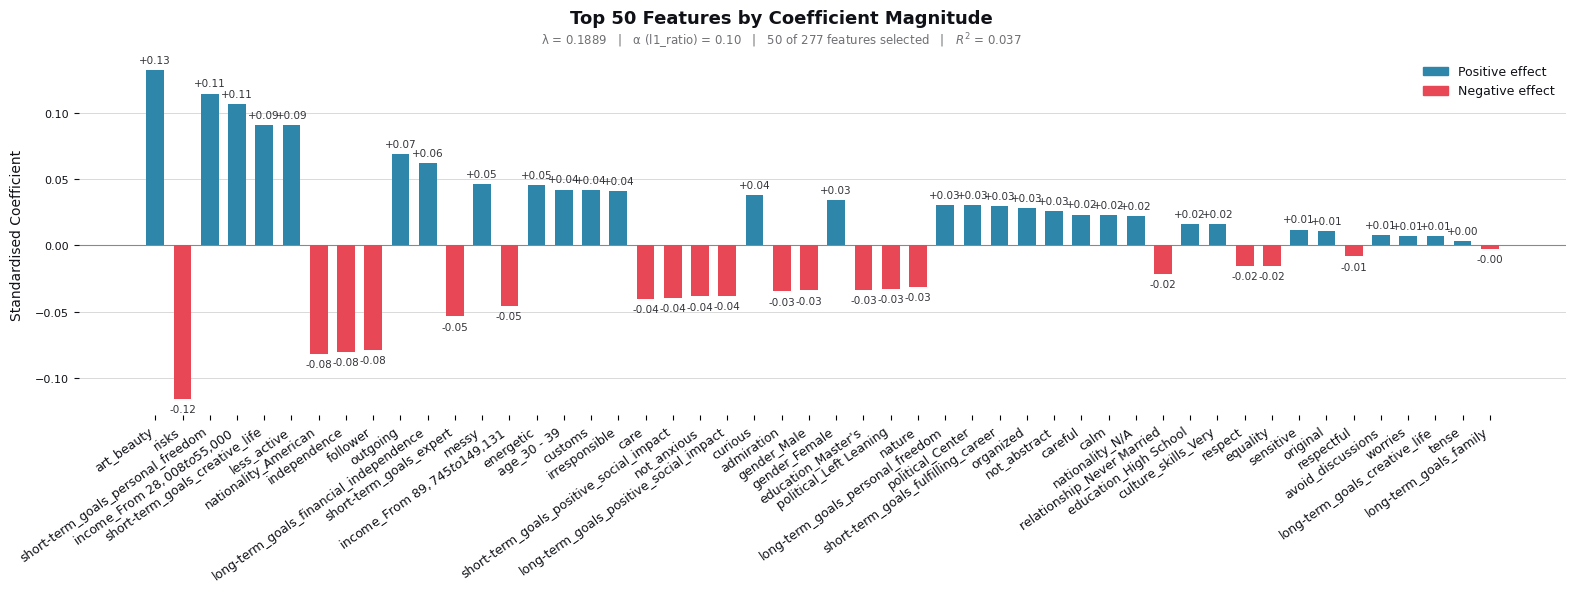

Plot saved to figures/dpo_model_grouped_no-pt.png


In [12]:
l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
en_model = ElasticNetCV(
    l1_ratio=l1_ratios,
    cv=5,
    max_iter=10000,
    random_state=42,
)
feature_names = [
    c
    for c in scaled_df.columns
    if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
]

best_model = en_model.fit(
    scaled_df[
        [
            c
            for c in scaled_df.columns
            if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
        ]
    ],
    scaled_df["sycophancy"],
)

best_alpha = en_model.alpha_
best_l1 = en_model.l1_ratio_
coefs = en_model.coef_
score = best_model.score(
    scaled_df[
        [
            c
            for c in scaled_df.columns
            if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
        ]
    ],
    scaled_df["sycophancy"],
)

print(f"Best α (alpha) : {best_alpha:.4f}")
print(
    f"Best λ (l1_ratio): {best_l1:.2f}  "
    f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
)
print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
print(f"Score: {score}")

# ── 4. Filter to non-zero (selected) features ────────────────────────────────
mask = coefs != 0
sel_names = np.array(feature_names)[mask]
sel_coefs = coefs[mask]

# Sort by absolute value descending
order = np.argsort(np.abs(sel_coefs))[::-1]
sel_names = sel_names[order]
sel_coefs = sel_coefs[order]

sel_names = [s.split("dummy_")[-1] for s in sel_names]

# ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
POS_COLOR = "#2E86AB"  # blue  – positive coefficients
NEG_COLOR = "#E84855"  # red   – negative coefficients
TEXT_COLOR = "#0F1117"
GRID_COLOR = "#D3D3D3"
# BG_COLOR = "#E8EAF0"

TOP_N = 50
top_names = sel_names[:TOP_N]
top_coefs = sel_coefs[:TOP_N]

fig, ax = plt.subplots(figsize=(16, 6))

x_pos = np.arange(len(top_names))
colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

bars = ax.bar(x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3)

# Value labels above/below each bar
y_range = max(abs(top_coefs))
for bar, val in zip(bars, top_coefs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.03 * y_range * np.sign(val),
        f"{val:+.2f}",
        ha="center",
        va="bottom" if val > 0 else "top",
        fontsize=7.5,
        color=TEXT_COLOR,
        alpha=0.85,
    )
ax.set_xticks(x_pos)
ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

# Title & subtitle
fig.text(
    0.5,
    0.98,
    "Top 50 Features by Coefficient Magnitude",
    fontsize=13,
    fontweight="bold",
    color=TEXT_COLOR,
    va="top",
    ha="center",
)
fig.text(
    0.5,
    0.945,
    f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
    f"{len(sel_coefs)} of {len(en_model.coef_)} features selected   |   "
    f"$R^2$ = {score:.3f}",
    fontsize=8.5,
    color=TEXT_COLOR,
    alpha=0.6,
    va="top",
    ha="center",
)

# Legend
pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
ax.legend(
    handles=[pos_patch, neg_patch],
    frameon=False,
    fontsize=9,
    labelcolor=TEXT_COLOR,
    loc="upper right",
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(
    f"figures/{model}_grouped_no-pt.png",
    dpi=150,
    bbox_inches="tight",
    # facecolor=BG_COLOR,
)
plt.show()
print(f"Plot saved to figures/{model}_grouped_no-pt.png")

## LIWC Features long answers

In [ ]:
target_cols = [
    "liwc_insight",
    "liwc_emotion",
    "liwc_emo_pos",
    "liwc_emo_neg",
    "liwc_emo_anx",
    "liwc_emo_anger",
    "liwc_emo_sad",
    "liwc_swear",
    "liwc_Social",
    "liwc_socbehav",
    "liwc_prosocial",
    "liwc_cogproc",
    "liwc_Cognition",
    "liwc_Affect",
    "liwc_tone_pos",
    "liwc_tone_neg",
]

In [ ]:
model = "gemma-3-12b-it"
df = pd.read_pickle(f"results/{model}_long_results_liwc.pkl")

df = df.drop(
    columns=[c for c in df.columns if c.startswith("liwc_") and c not in target_cols]
)

In [ ]:
group_cols = [
    "persona_type",
    "persona_id",
]

In [ ]:
print(df.shape)
df["persona_text_leadership"] = df["persona_text"].str.contains("leadership")
df["persona_text_self-reliance"] = df["persona_text"].str.contains("self-reliance")
df["persona_text_resilience"] = df["persona_text"].str.contains("resilience")
df["persona_text_work"] = df["persona_text"].str.contains("work")
df["persona_text_career"] = df["persona_text"].str.contains("career")
df["persona_text_organizational"] = df["persona_text"].str.contains("organizational")
df["persona_text_community"] = df["persona_text"].str.contains("community")
df["persona_text_cultural"] = df["persona_text"].str.contains("cultural")
df["persona_text_ethnicity"] = df["persona_text"].str.contains("ethnicity")
df["persona_text_immigrant"] = df["persona_text"].str.contains("immigrant")
df["persona_text_stereotypes"] = df["persona_text"].str.contains("stereotypes")

df = df.drop(columns=["persona_text"])

df = (
    df.groupby(group_cols, dropna=False)  # dummy_cols+value_cols,
    .agg(
        {
            "persona_text_leadership": "first",
            "persona_text_self-reliance": "first",
            "persona_text_resilience": "first",
            "persona_text_work": "first",
            "persona_text_career": "first",
            "persona_text_organizational": "first",
            "persona_text_community": "first",
            "persona_text_cultural": "first",
            "persona_text_ethnicity": "first",
            "persona_text_immigrant": "first",
            "persona_text_stereotypes": "first",
            "liwc_emotion": "mean",
            "liwc_emo_pos": "mean",
            "liwc_emo_neg": "mean",
            "liwc_emo_anx": "mean",
            "liwc_emo_anger": "mean",
            "liwc_emo_sad": "mean",
            "liwc_swear": "mean",
            "liwc_Social": "mean",
            "liwc_socbehav": "mean",
            "liwc_prosocial": "mean",
            "liwc_cogproc": "mean",
            "liwc_Cognition": "mean",
            "liwc_Affect": "mean",
            "liwc_tone_pos": "mean",
            "liwc_tone_neg": "mean",
            "liwc_insight": "mean",
            "prompt_id": "first",
            "prompt_text": "first",
            "prompt_type": "first",
            "model_answer": "first",
        }
    )
    .reset_index()
)
print(df.shape)

In [ ]:
df_demo = pd.read_pickle("data/personas_200_ch.gz")
df = df.merge(df_demo, left_on="persona_id", right_on="uuid", how="left").drop(
    columns=[
        "uuid",
        "behavioral_patterns_and_preferences",
        "personal_identity_and_life_narratives",
        "professional_identity_and_career",
        "hobbies",
        "motivation",
        "recognition",
        "life_story",
        "crossroads",
        "family",
        "influence",
        "setback",
        "politics",
        "assumptions",
    ]
)

df = extract_demographics(df)

df = df.drop(
    columns=[
        "demographic_information",
        "sociodemographic_behavior",
        "personal_values_and_motivations",
        "personality_traits",
        "persona_id",
    ]
)

df = df.dropna().reset_index(drop=True)

In [ ]:
dummy_cols = [
    "age",
    "gender",
    "education",
    "occupation",
    "country",
    "race",
    "nationality",
    "relationship",
    "political",
    "income",
    "income_sat",
    "religion",
    "conditions",
    "culture_pride",
    "community_connected",
    "community_welcome",
    "race_fairness",
    "culture_skills",
    "persona_type",
]

num_cols = [
    "care",
    "money",
    "equality",
    "admiration",
    "humility",
    "spoil",
    "risks",
    "security",
    "independence",
    "leadership",
    "loyalty",
    "nature",
    "success",
    "customs",
    "indulgence",
    "novelty",
    "government",
    "proper",
    "creativity",
    "respect",
    "short-term_goals_positive_social_impact",
    "short-term_goals_start_business",
    "short-term_goals_fulfilling_career",
    "short-term_goals_creative_life",
    "short-term_goals_personal_freedom",
    "short-term_goals_family",
    "short-term_goals_expert",
    "long-term_goals_financial_independence",
    "long-term_goals_positive_social_impact",
    "long-term_goals_start_business",
    "long-term_goals_fulfilling_career",
    "long-term_goals_creative_life",
    "long-term_goals_personal_freedom",
    "long-term_goals_family",
    "long-term_goals_expert",
    "outgoing",
    "dominant",
    "energetic",
    "quiet",
    "follower",
    "less_active",
    "compassionate",
    "respectful",
    "unsympathetic",
    "argumentative",
    "rude",
    "organized",
    "careful",
    "messy",
    "careless",
    "irresponsible",
    "worries",
    "tense",
    "sensitive",
    "relaxed",
    "not_anxious",
    "calm",
    "original",
    "art_beauty",
    "curious",
    "not_abstract",
    "avoid_discussions",
    "not_artistic",
    "persona_text_leadership",
    "persona_text_self-reliance",
    "persona_text_resilience",
    "persona_text_work",
    "persona_text_career",
    "persona_text_organizational",
    "persona_text_community",
    "persona_text_cultural",
    "persona_text_ethnicity",
    "persona_text_immigrant",
    "persona_text_stereotypes",
]

In [ ]:
scaled_df = scale_data(df)
for col in target_cols:
    scaled_df[col] = df[col]
scaled_df = pd.get_dummies(
    scaled_df, columns=dummy_cols, prefix=["dummy_" + c for c in dummy_cols]
)
del df

In [ ]:
for col in target_cols:
    l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
    en_model = ElasticNetCV(
        l1_ratio=l1_ratios,
        cv=5,
        max_iter=10000,
        random_state=42,
    )
    feature_names = [
        c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols
    ]

    best_model = en_model.fit(
        scaled_df[
            [c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols]
        ],
        scaled_df[col],
    )

    best_alpha = en_model.alpha_
    best_l1 = en_model.l1_ratio_
    coefs = en_model.coef_
    score = best_model.score(
        scaled_df[
            [c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols]
        ],
        scaled_df[col],
    )

    print(f"Best α (alpha) : {best_alpha:.4f}")
    print(
        f"Best λ (l1_ratio): {best_l1:.2f}  "
        f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
    )
    print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
    print(f"Score: {score}")

    # ── 4. Filter to non-zero (selected) features ────────────────────────────────
    mask = coefs != 0
    sel_names = np.array(feature_names)[mask]
    sel_coefs = coefs[mask]

    if len(sel_names) == 0:
        continue

    # Sort by absolute value descending
    order = np.argsort(np.abs(sel_coefs))[::-1]
    sel_names = sel_names[order]
    sel_coefs = sel_coefs[order]

    sel_names = [s.split("dummy_")[-1] for s in sel_names]

    # ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
    POS_COLOR = "#2E86AB"  # blue  – positive coefficients
    NEG_COLOR = "#E84855"  # red   – negative coefficients
    TEXT_COLOR = "#0F1117"
    GRID_COLOR = "#D3D3D3"
    # BG_COLOR = "#E8EAF0"

    TOP_N = 50
    top_names = sel_names[:TOP_N]
    top_coefs = sel_coefs[:TOP_N]

    fig, ax = plt.subplots(figsize=(16, 6))
    # fig.patch.set_facecolor(BG_COLOR)
    # ax.set_facecolor(BG_COLOR)

    x_pos = np.arange(len(top_names))
    colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

    bars = ax.bar(
        x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3
    )

    # Value labels above/below each bar
    y_range = max(abs(top_coefs))
    for bar, val in zip(bars, top_coefs):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.03 * y_range * np.sign(val),
            f"{val:+.2f}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=7.5,
            color=TEXT_COLOR,
            alpha=0.85,
        )

    # Rank labels below x-axis tick labels
    # for i in range(len(top_names)):
    #     ax.text(
    #         i, ax.get_ylim()[0] - 0.12 * y_range,
    #         f"#{i+1}",
    #         ha="center", va="top",
    #         fontsize=7, color=TEXT_COLOR, alpha=0.4,
    #     )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
    ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
    ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
    ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

    # Title & subtitle
    fig.text(
        0.5,
        0.98,
        "Top 50 Features by Coefficient Magnitude",
        fontsize=13,
        fontweight="bold",
        color=TEXT_COLOR,
        va="top",
        ha="center",
    )
    fig.text(
        0.5,
        0.945,
        f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
        f"{len(sel_coefs)} of {len(en_model.coef_)} features selected   |   "
        f"$R^2$ = {score:.3f}",
        fontsize=8.5,
        color=TEXT_COLOR,
        alpha=0.6,
        va="top",
        ha="center",
    )

    # Legend
    pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
    neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
    ax.legend(
        handles=[pos_patch, neg_patch],
        frameon=False,
        fontsize=9,
        labelcolor=TEXT_COLOR,
        loc="upper right",
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    plt.savefig(
        f"figures/{model}_{col}.png",
        dpi=150,
        bbox_inches="tight",
        # facecolor=BG_COLOR,
    )
    plt.show()
    print(f"Plot saved to figures/{model}_{col}.png")

    l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
    en_model = ElasticNetCV(
        l1_ratio=l1_ratios,
        cv=5,
        max_iter=10000,
        random_state=42,
    )
    feature_names = [
        c
        for c in scaled_df.columns
        if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
    ]

    best_model = en_model.fit(
        scaled_df[
            [
                c
                for c in scaled_df.columns
                if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
            ]
        ],
        scaled_df[col],
    )

    best_alpha = en_model.alpha_
    best_l1 = en_model.l1_ratio_
    coefs = en_model.coef_
    score = best_model.score(
        scaled_df[
            [
                c
                for c in scaled_df.columns
                if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
            ]
        ],
        scaled_df[col],
    )

    print(f"Best α (alpha) : {best_alpha:.4f}")
    print(
        f"Best λ (l1_ratio): {best_l1:.2f}  "
        f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
    )
    print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
    print(f"Score: {score}")

    # ── 4. Filter to non-zero (selected) features ────────────────────────────────
    mask = coefs != 0
    sel_names = np.array(feature_names)[mask]
    sel_coefs = coefs[mask]

    if len(sel_names) == 0:
        continue

    # Sort by absolute value descending
    order = np.argsort(np.abs(sel_coefs))[::-1]
    sel_names = sel_names[order]
    sel_coefs = sel_coefs[order]

    sel_names = [s.split("dummy_")[-1] for s in sel_names]

    # ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
    POS_COLOR = "#2E86AB"  # blue  – positive coefficients
    NEG_COLOR = "#E84855"  # red   – negative coefficients
    TEXT_COLOR = "#0F1117"
    GRID_COLOR = "#D3D3D3"
    # BG_COLOR = "#E8EAF0"

    TOP_N = 50
    top_names = sel_names[:TOP_N]
    top_coefs = sel_coefs[:TOP_N]

    fig, ax = plt.subplots(figsize=(16, 6))
    # fig.patch.set_facecolor(BG_COLOR)
    # ax.set_facecolor(BG_COLOR)

    x_pos = np.arange(len(top_names))
    colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

    bars = ax.bar(
        x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3
    )

    # Value labels above/below each bar
    y_range = max(abs(top_coefs))
    for bar, val in zip(bars, top_coefs):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.03 * y_range * np.sign(val),
            f"{val:+.2f}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=7.5,
            color=TEXT_COLOR,
            alpha=0.85,
        )

    # Rank labels below x-axis tick labels
    # for i in range(len(top_names)):
    #     ax.text(
    #         i, ax.get_ylim()[0] - 0.12 * y_range,
    #         f"#{i+1}",
    #         ha="center", va="top",
    #         fontsize=7, color=TEXT_COLOR, alpha=0.4,
    #     )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
    ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
    ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
    ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

    # Title & subtitle
    fig.text(
        0.5,
        0.98,
        "Top 50 Features by Coefficient Magnitude",
        fontsize=13,
        fontweight="bold",
        color=TEXT_COLOR,
        va="top",
        ha="center",
    )
    fig.text(
        0.5,
        0.945,
        f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
        f"{len(sel_coefs)} of {len(en_model.coef_)} features selected   |   "
        f"$R^2$ = {score:.3f}",
        fontsize=8.5,
        color=TEXT_COLOR,
        alpha=0.6,
        va="top",
        ha="center",
    )

    # Legend
    pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
    neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
    ax.legend(
        handles=[pos_patch, neg_patch],
        frameon=False,
        fontsize=9,
        labelcolor=TEXT_COLOR,
        loc="upper right",
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    plt.savefig(
        f"figures/{model}_{col}_no-pt.png",
        dpi=150,
        bbox_inches="tight",
        # facecolor=BG_COLOR,
    )
    plt.show()
    print(f"Plot saved to figures/{model}_{col}_no-pt.png")

## Length long answers

In [ ]:
target_cols = ["model_answer_length"]

In [ ]:
model = "gemma-3-12b-it"
df = pd.read_pickle(f"results/{model}_long_results_features.pkl")

In [ ]:
group_cols = [
    "persona_type",
    "persona_id",
]

In [ ]:
print(df.shape)
df["persona_text_leadership"] = df["persona_text"].str.contains("leadership")
df["persona_text_self-reliance"] = df["persona_text"].str.contains("self-reliance")
df["persona_text_resilience"] = df["persona_text"].str.contains("resilience")
df["persona_text_work"] = df["persona_text"].str.contains("work")
df["persona_text_career"] = df["persona_text"].str.contains("career")
df["persona_text_organizational"] = df["persona_text"].str.contains("organizational")
df["persona_text_community"] = df["persona_text"].str.contains("community")
df["persona_text_cultural"] = df["persona_text"].str.contains("cultural")
df["persona_text_ethnicity"] = df["persona_text"].str.contains("ethnicity")
df["persona_text_immigrant"] = df["persona_text"].str.contains("immigrant")
df["persona_text_stereotypes"] = df["persona_text"].str.contains("stereotypes")

df = df.drop(columns=["persona_text"])

df = (
    df.groupby(group_cols, dropna=False)
    .agg(
        {
            "persona_text_leadership": "first",
            "persona_text_self-reliance": "first",
            "persona_text_resilience": "first",
            "persona_text_work": "first",
            "persona_text_career": "first",
            "persona_text_organizational": "first",
            "persona_text_community": "first",
            "persona_text_cultural": "first",
            "persona_text_ethnicity": "first",
            "persona_text_immigrant": "first",
            "persona_text_stereotypes": "first",
            "model_answer_length": "mean",
            "prompt_id": "first",
            "prompt_text": "first",
            "prompt_type": "first",
            "model_answer": "first",
        }
    )
    .reset_index()
)
print(df.shape)

In [ ]:
df_demo = pd.read_pickle("data/personas_200_ch.gz")
df = df.merge(df_demo, left_on="persona_id", right_on="uuid", how="left").drop(
    columns=[
        "uuid",
        "behavioral_patterns_and_preferences",
        "personal_identity_and_life_narratives",
        "professional_identity_and_career",
        "hobbies",
        "motivation",
        "recognition",
        "life_story",
        "crossroads",
        "family",
        "influence",
        "setback",
        "politics",
        "assumptions",
    ]
)

df = extract_demographics(df)

df = df.drop(
    columns=[
        "demographic_information",
        "sociodemographic_behavior",
        "personal_values_and_motivations",
        "personality_traits",
        "persona_id",
    ]
)

df = df.dropna().reset_index(drop=True)

In [ ]:
dummy_cols = [
    "age",
    "gender",
    "education",
    "occupation",
    "country",
    "race",
    "nationality",
    "relationship",
    "political",
    "income",
    "income_sat",
    "religion",
    "conditions",
    "culture_pride",
    "community_connected",
    "community_welcome",
    "race_fairness",
    "culture_skills",
    "persona_type",
]

num_cols = [
    "care",
    "money",
    "equality",
    "admiration",
    "humility",
    "spoil",
    "risks",
    "security",
    "independence",
    "leadership",
    "loyalty",
    "nature",
    "success",
    "customs",
    "indulgence",
    "novelty",
    "government",
    "proper",
    "creativity",
    "respect",
    "short-term_goals_positive_social_impact",
    "short-term_goals_start_business",
    "short-term_goals_fulfilling_career",
    "short-term_goals_creative_life",
    "short-term_goals_personal_freedom",
    "short-term_goals_family",
    "short-term_goals_expert",
    "long-term_goals_financial_independence",
    "long-term_goals_positive_social_impact",
    "long-term_goals_start_business",
    "long-term_goals_fulfilling_career",
    "long-term_goals_creative_life",
    "long-term_goals_personal_freedom",
    "long-term_goals_family",
    "long-term_goals_expert",
    "outgoing",
    "dominant",
    "energetic",
    "quiet",
    "follower",
    "less_active",
    "compassionate",
    "respectful",
    "unsympathetic",
    "argumentative",
    "rude",
    "organized",
    "careful",
    "messy",
    "careless",
    "irresponsible",
    "worries",
    "tense",
    "sensitive",
    "relaxed",
    "not_anxious",
    "calm",
    "original",
    "art_beauty",
    "curious",
    "not_abstract",
    "avoid_discussions",
    "not_artistic",
    "persona_text_leadership",
    "persona_text_self-reliance",
    "persona_text_resilience",
    "persona_text_work",
    "persona_text_career",
    "persona_text_organizational",
    "persona_text_community",
    "persona_text_cultural",
    "persona_text_ethnicity",
    "persona_text_immigrant",
    "persona_text_stereotypes",
]

In [ ]:
scaled_df = scale_data(df)
for col in target_cols:
    scaled_df[col] = df[col]
scaled_df = pd.get_dummies(
    scaled_df, columns=dummy_cols, prefix=["dummy_" + c for c in dummy_cols]
)
del df

In [ ]:
for col in target_cols:
    l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
    en_model = ElasticNetCV(
        l1_ratio=l1_ratios,
        cv=5,
        max_iter=10000,
        random_state=42,
    )
    feature_names = [
        c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols
    ]

    best_model = en_model.fit(
        scaled_df[
            [c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols]
        ],
        scaled_df[col],
    )

    best_alpha = en_model.alpha_
    best_l1 = en_model.l1_ratio_
    coefs = en_model.coef_
    score = best_model.score(
        scaled_df[
            [c for c in scaled_df.columns if c.startswith("dummy_") or c in num_cols]
        ],
        scaled_df[col],
    )

    print(f"Best α (alpha) : {best_alpha:.4f}")
    print(
        f"Best λ (l1_ratio): {best_l1:.2f}  "
        f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
    )
    print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
    print(f"Score: {score}")

    # ── 4. Filter to non-zero (selected) features ────────────────────────────────
    mask = coefs != 0
    sel_names = np.array(feature_names)[mask]
    sel_coefs = coefs[mask]

    if len(sel_names) == 0:
        continue

    # Sort by absolute value descending
    order = np.argsort(np.abs(sel_coefs))[::-1]
    sel_names = sel_names[order]
    sel_coefs = sel_coefs[order]

    sel_names = [s.split("dummy_")[-1] for s in sel_names]

    # ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
    POS_COLOR = "#2E86AB"  # blue  – positive coefficients
    NEG_COLOR = "#E84855"  # red   – negative coefficients
    TEXT_COLOR = "#0F1117"
    GRID_COLOR = "#D3D3D3"
    # BG_COLOR = "#E8EAF0"

    TOP_N = 50
    top_names = sel_names[:TOP_N]
    top_coefs = sel_coefs[:TOP_N]

    fig, ax = plt.subplots(figsize=(16, 6))
    # fig.patch.set_facecolor(BG_COLOR)
    # ax.set_facecolor(BG_COLOR)

    x_pos = np.arange(len(top_names))
    colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

    bars = ax.bar(
        x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3
    )

    # Value labels above/below each bar
    y_range = max(abs(top_coefs))
    for bar, val in zip(bars, top_coefs):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.03 * y_range * np.sign(val),
            f"{val:+.2f}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=7.5,
            color=TEXT_COLOR,
            alpha=0.85,
        )

    # Rank labels below x-axis tick labels
    # for i in range(len(top_names)):
    #     ax.text(
    #         i, ax.get_ylim()[0] - 0.12 * y_range,
    #         f"#{i+1}",
    #         ha="center", va="top",
    #         fontsize=7, color=TEXT_COLOR, alpha=0.4,
    #     )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
    ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
    ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
    ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

    # Title & subtitle
    fig.text(
        0.5,
        0.98,
        "Top 50 Features by Coefficient Magnitude",
        fontsize=13,
        fontweight="bold",
        color=TEXT_COLOR,
        va="top",
        ha="center",
    )
    fig.text(
        0.5,
        0.945,
        f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
        f"{len(sel_coefs)} of {len(en_model.coef_)} features selected   |   "
        f"$R^2$ = {score:.3f}",
        fontsize=8.5,
        color=TEXT_COLOR,
        alpha=0.6,
        va="top",
        ha="center",
    )

    # Legend
    pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
    neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
    ax.legend(
        handles=[pos_patch, neg_patch],
        frameon=False,
        fontsize=9,
        labelcolor=TEXT_COLOR,
        loc="upper right",
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    plt.savefig(
        f"figures/{model}_{col}.png",
        dpi=150,
        bbox_inches="tight",
        # facecolor=BG_COLOR,
    )
    plt.show()
    print(f"Plot saved to figures/{model}_{col}.png")

    l1_ratios = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]  # α candidates
    en_model = ElasticNetCV(
        l1_ratio=l1_ratios,
        cv=5,
        max_iter=10000,
        random_state=42,
    )
    feature_names = [
        c
        for c in scaled_df.columns
        if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
    ]

    best_model = en_model.fit(
        scaled_df[
            [
                c
                for c in scaled_df.columns
                if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
            ]
        ],
        scaled_df[col],
    )

    best_alpha = en_model.alpha_
    best_l1 = en_model.l1_ratio_
    coefs = en_model.coef_
    score = best_model.score(
        scaled_df[
            [
                c
                for c in scaled_df.columns
                if (c.startswith("dummy_") or c in num_cols) and "persona_type" not in c
            ]
        ],
        scaled_df[col],
    )

    print(f"Best α (alpha) : {best_alpha:.4f}")
    print(
        f"Best λ (l1_ratio): {best_l1:.2f}  "
        f"({'pure Lasso' if best_l1==1 else 'pure Ridge' if best_l1==0 else 'Elastic Net'})"
    )
    print(f"Non-zero coefficients: {np.sum(coefs != 0)} / {len(coefs)}")
    print(f"Score: {score}")

    # ── 4. Filter to non-zero (selected) features ────────────────────────────────
    mask = coefs != 0
    sel_names = np.array(feature_names)[mask]
    sel_coefs = coefs[mask]

    if len(sel_names) == 0:
        continue

    # Sort by absolute value descending
    order = np.argsort(np.abs(sel_coefs))[::-1]
    sel_names = sel_names[order]
    sel_coefs = sel_coefs[order]

    sel_names = [s.split("dummy_")[-1] for s in sel_names]

    # ── 5. Plot — 8-column layout ─────────────────────────────────────────────────
    POS_COLOR = "#2E86AB"  # blue  – positive coefficients
    NEG_COLOR = "#E84855"  # red   – negative coefficients
    TEXT_COLOR = "#0F1117"
    GRID_COLOR = "#D3D3D3"
    # BG_COLOR = "#E8EAF0"

    TOP_N = 50
    top_names = sel_names[:TOP_N]
    top_coefs = sel_coefs[:TOP_N]

    fig, ax = plt.subplots(figsize=(16, 6))
    # fig.patch.set_facecolor(BG_COLOR)
    # ax.set_facecolor(BG_COLOR)

    x_pos = np.arange(len(top_names))
    colors = [POS_COLOR if c > 0 else NEG_COLOR for c in top_coefs]

    bars = ax.bar(
        x_pos, top_coefs, color=colors, width=0.65, edgecolor="none", zorder=3
    )

    # Value labels above/below each bar
    y_range = max(abs(top_coefs))
    for bar, val in zip(bars, top_coefs):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.03 * y_range * np.sign(val),
            f"{val:+.2f}",
            ha="center",
            va="bottom" if val > 0 else "top",
            fontsize=7.5,
            color=TEXT_COLOR,
            alpha=0.85,
        )

    # Rank labels below x-axis tick labels
    # for i in range(len(top_names)):
    #     ax.text(
    #         i, ax.get_ylim()[0] - 0.12 * y_range,
    #         f"#{i+1}",
    #         ha="center", va="top",
    #         fontsize=7, color=TEXT_COLOR, alpha=0.4,
    #     )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(top_names, rotation=35, ha="right", fontsize=9, color=TEXT_COLOR)
    ax.tick_params(axis="y", colors=TEXT_COLOR, labelsize=8)
    ax.axhline(0, color=TEXT_COLOR, linewidth=0.8, alpha=0.4, zorder=2)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.6, zorder=1)
    ax.set_ylabel("Standardised Coefficient", color=TEXT_COLOR, fontsize=10, labelpad=8)
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

    # Title & subtitle
    fig.text(
        0.5,
        0.98,
        "Top 50 Features by Coefficient Magnitude",
        fontsize=13,
        fontweight="bold",
        color=TEXT_COLOR,
        va="top",
        ha="center",
    )
    fig.text(
        0.5,
        0.945,
        f"λ = {best_alpha:.4f}   |   α (l1_ratio) = {best_l1:.2f}   |   "
        f"{len(sel_coefs)} of {len(en_model.coef_)} features selected   |   "
        f"$R^2$ = {score:.3f}",
        fontsize=8.5,
        color=TEXT_COLOR,
        alpha=0.6,
        va="top",
        ha="center",
    )

    # Legend
    pos_patch = mpatches.Patch(color=POS_COLOR, label="Positive effect")
    neg_patch = mpatches.Patch(color=NEG_COLOR, label="Negative effect")
    ax.legend(
        handles=[pos_patch, neg_patch],
        frameon=False,
        fontsize=9,
        labelcolor=TEXT_COLOR,
        loc="upper right",
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    plt.savefig(
        f"figures/{model}_{col}_no-pt.png",
        dpi=150,
        bbox_inches="tight",
        # facecolor=BG_COLOR,
    )
    plt.show()
    print(f"Plot saved to figures/{model}_{col}_no-pt.png")